# Fig. 3: layer-resolved tight-binding LDOS across the (+⁴−) region


    Energy derivative of the tight-binding LDOS of each of the six graphene layers, along a line across
    the (+⁴−) strip embedded in (+⁵) (system 1, the geometry of Fig. 2e,f). Layer 1 is the top layer,
    the one probed by the STM tip; in the data files the layers are numbered from the substrate
    (file layer 6 = displayed layer 1).

    Data: `ldos_system1_layer{n}_SAJAT.txt.gz` (LDOS(E, x), 1000 energy rows on
    E = −0.4995 … 0.4995 eV in 1 meV steps) and `x_system1_layer{n}_SAJAT.txt` (x in Å), n = 1 … 6.


Paper: Kandrai, K. *et al.* One-way electron mirrors from single-layer stacking shifts in rhombohedral graphite. Preprint at https://arxiv.org/abs/2610.20905 (2026).

In [1]:
import os
import sys
import requests
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
import matplotlib.gridspec as gridspec

In [2]:
print('python', sys.version.split()[0])
print('numpy', np.__version__)
print('matplotlib', matplotlib.__version__)

python 3.13.5
numpy 2.1.3
matplotlib 3.10.0


In [3]:
# figure style of the paper: scienceplots if it is installed, plain matplotlib otherwise
try:
    import scienceplots  # noqa: F401
    plt.style.use(['science', 'no-latex', 'nature', 'std-colors'])
except ImportError:
    pass
matplotlib.rcParams['pdf.fonttype'] = 42   # editable text in Inkscape / Illustrator
matplotlib.rcParams['ps.fonttype'] = 42
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['figure.dpi'] = 110

In [4]:
# Data files are downloaded from Zenodo into DATA_DIR if they are not there yet.
ZENODO_RECORD = '23419464'   # record number of the data set, https://zenodo.org/records/<ZENODO_RECORD>
DATA_DIR = 'data'

FILES = ['ldos_system1_layer1_SAJAT.txt.gz', 'ldos_system1_layer2_SAJAT.txt.gz', 'ldos_system1_layer3_SAJAT.txt.gz', 'ldos_system1_layer4_SAJAT.txt.gz', 'ldos_system1_layer5_SAJAT.txt.gz', 'ldos_system1_layer6_SAJAT.txt.gz', 'x_system1_layer1_SAJAT.txt', 'x_system1_layer2_SAJAT.txt', 'x_system1_layer3_SAJAT.txt', 'x_system1_layer4_SAJAT.txt', 'x_system1_layer5_SAJAT.txt', 'x_system1_layer6_SAJAT.txt']


def get_data(filename, record=ZENODO_RECORD, data_dir=DATA_DIR):
    """Return the local path of a data file, downloading it from Zenodo first if needed."""
    path = os.path.join(data_dir, filename)
    if os.path.exists(path):
        return path
    os.makedirs(data_dir, exist_ok=True)
    url = f'https://zenodo.org/records/{record}/files/{requests.utils.quote(filename)}?download=1'
    print(f'Downloading {filename} ...')
    with requests.get(url, stream=True, timeout=600) as r:
        r.raise_for_status()
        with open(path, 'wb') as fh:
            for chunk in r.iter_content(chunk_size=1 << 20):
                fh.write(chunk)
    print(f'  saved to {path}')
    return path


for f in FILES:
    get_data(f)

In [5]:
def extent_of(da, xdim, ydim):
    """imshow extent (outer pixel edges) of an xarray DataArray with uniform coordinates."""
    x, y = da[xdim].values, da[ydim].values
    dx = (x[-1] - x[0]) / (x.size - 1)
    dy = (y[-1] - y[0]) / (y.size - 1)
    return [x[0] - dx / 2, x[-1] + dx / 2, y[0] - dy / 2, y[-1] + dy / 2]


def extent_xy(x, y):
    """imshow extent (outer pixel edges) for two uniform coordinate arrays."""
    dx = (x[-1] - x[0]) / (x.size - 1)
    dy = (y[-1] - y[0]) / (y.size - 1)
    return [x[0] - dx / 2, x[-1] + dx / 2, y[0] - dy / 2, y[-1] + dy / 2]

In [6]:
E = np.arange(-0.4995, 0.5, 0.001)   # eV
Elim = 0.4
VMAX_LDOS = 0.02 * 1000              # the LDOS is plotted as ldos * 1000
GRAD_LIM = 0.2 * 100                 # the derivative is plotted as d(LDOS)/dE * 100
SIGMA = (4, 0)                       # Gaussian smoothing along the energy axis, 4 meV; none along x


def load_layer(layer):
    """dist_nm, ldos(E, x) of one file layer (1 = substrate side, 6 = top)."""
    ldos = np.loadtxt(get_data(f'ldos_system1_layer{layer}_SAJAT.txt.gz'))
    x = np.loadtxt(get_data(f'x_system1_layer{layer}_SAJAT.txt'))
    assert ldos.shape[0] == E.size
    return (x - x[0]) / 10, ldos


layers = {layer: load_layer(layer) for layer in range(1, 7)}
E_mask = (E >= -Elim) & (E <= Elim)
E_crop = E[E_mask]

In [7]:
def plot_layer_row(shown_layers, data, cmap, vmin, vmax, cbar_label, figsize=(14, 3.6)):
    """Three layers side by side, sharing the energy axis, with one colour bar.

    `shown_layers` are displayed layer numbers (1 = top layer); data[shown] = (dist_nm, array(E_crop, x)).
    """
    fig = plt.figure(figsize=figsize)
    gs = gridspec.GridSpec(1, len(shown_layers) + 1, figure=fig,
                           width_ratios=[1] * len(shown_layers) + [0.04], wspace=0.08)
    axs = []
    for i, shown in enumerate(shown_layers):
        ax = fig.add_subplot(gs[0, i], sharey=axs[0] if axs else None)
        dist_nm, arr = data[shown]
        im = ax.imshow(arr, cmap=cmap, aspect='auto', origin='lower',
                       extent=extent_xy(dist_nm, E_crop), vmin=vmin, vmax=vmax)
        ax.set_title(f'layer {shown}')
        ax.set_xlabel('distance (nm)')
        if i == 0:
            ax.set_ylabel('energy (eV)')
        else:
            ax.tick_params(axis='y', labelleft=False)
        axs.append(ax)
    fig.colorbar(im, cax=fig.add_subplot(gs[0, -1])).set_label(cbar_label)
    return fig, axs


# smoothed LDOS and its energy derivative, keyed by the displayed layer number (1 = top = file layer 6)
ldos_smooth = {7 - layer: (dist_nm, gaussian_filter(ldos, sigma=SIGMA))
               for layer, (dist_nm, ldos) in layers.items()}
grad_shown = {shown: (dist_nm, (np.gradient(ldos_s, E, axis=0) * 100)[E_mask, :])
              for shown, (dist_nm, ldos_s) in ldos_smooth.items()}
ldos_shown = {shown: (dist_nm, ldos_s[E_mask, :] * 1000)
              for shown, (dist_nm, ldos_s) in ldos_smooth.items()}

## Energy derivative of the LDOS, layers 1-3 and 4-6 (the panels of Fig. 3)

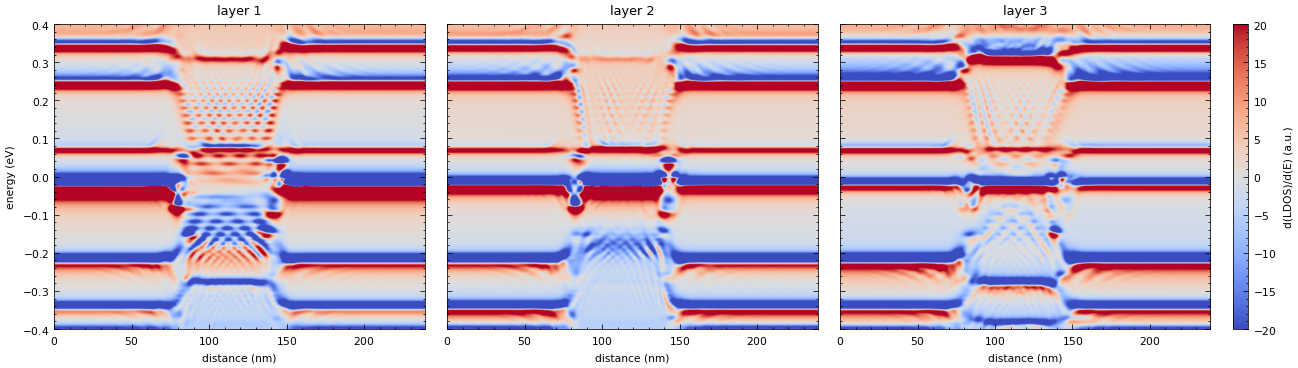

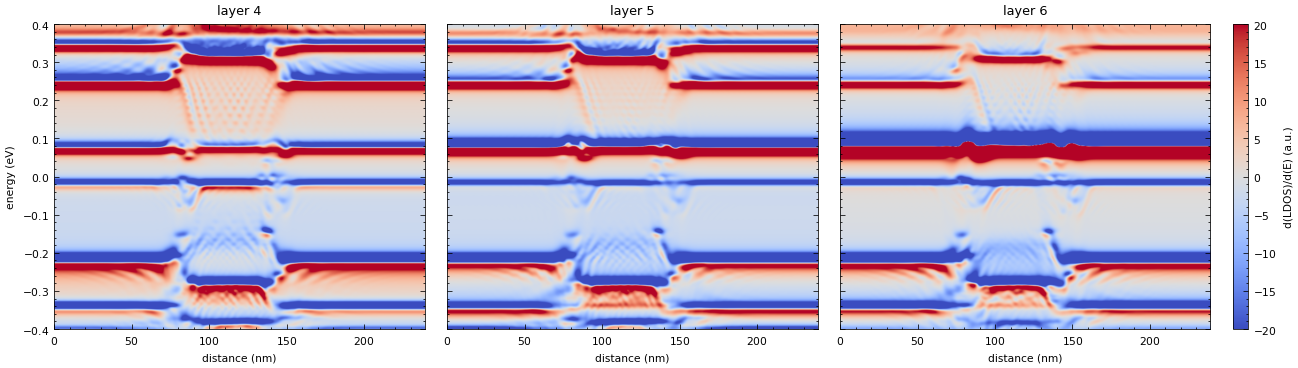

In [8]:
for shown_layers in ((1, 2, 3), (4, 5, 6)):
    plot_layer_row(shown_layers, grad_shown, 'coolwarm', -GRAD_LIM, GRAD_LIM, 'd(LDOS)/d(E) (a.u.)')
    plt.show()

## The LDOS itself, for reference

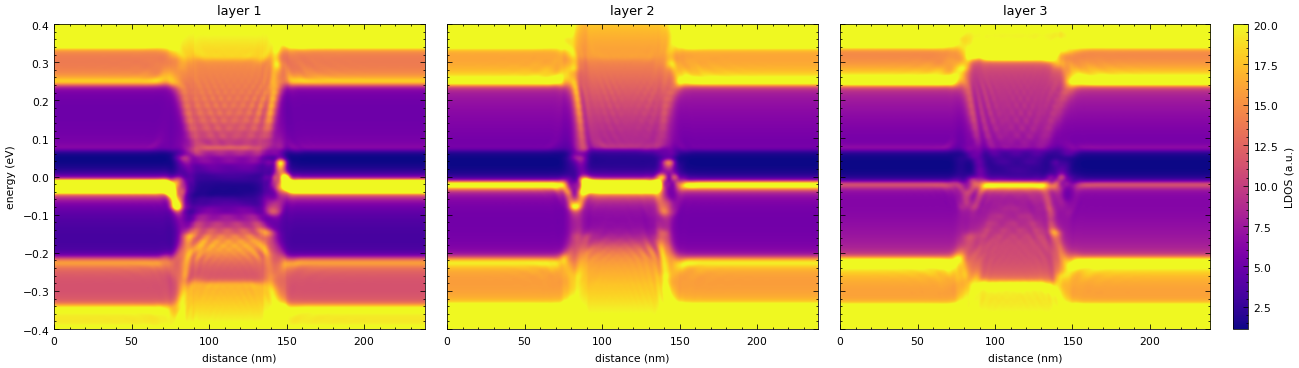

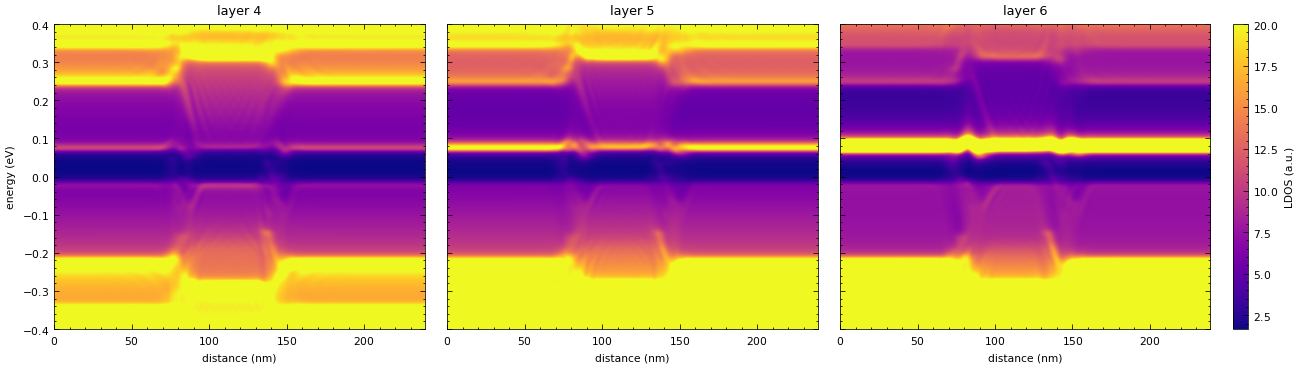

In [9]:
for shown_layers in ((1, 2, 3), (4, 5, 6)):
    plot_layer_row(shown_layers, ldos_shown, 'plasma', None, VMAX_LDOS, 'LDOS (a.u.)')
    plt.show()